# Bird species classification: supervised CNN

Train a small CNN directly on the 200 labelled clips, then predict the species of the 200 test clips.

In [25]:
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from pathlib import Path
from joblib import Parallel, delayed
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path("/gws/ssde/j25b/iecdt/bio_practicals/bioacoustic")  # shared practical folder, so copies of this notebook work anywhere
DATA_DIR = ROOT / "data"
SR = 32000
N_MELS = 64
N_FRAMES = 312

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## Loading the data

Each clip is turned into a log-mel spectrogram of shape (64 mel bands × 312 time frames), scaled to lie between 0 and 1. (mel band is effectively logarithmic frequency band - meant to mimic human hearing)

In [26]:
def load_mel(path):
    y, _ = librosa.load(path, sr=SR, duration=5.0)
    y = librosa.util.fix_length(y, size=5 * SR)  # zero-pad clips shorter than 5 s
    mel = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=1024, hop_length=512, n_mels=N_MELS, fmin=50, fmax=14000)
    mel = librosa.power_to_db(mel, ref=np.max, top_db=80)
    return (mel[:, :N_FRAMES] / 80 + 1).astype(np.float32) #drop last time frame (312 is nice divisible number), divide by top_dB, scale [0,1]


def load_files(paths):
    return np.stack(Parallel(n_jobs=8)(delayed(load_mel)(p) for p in paths))

In [27]:
labels = pd.read_csv(DATA_DIR / "labelled" / "labels.csv")
classes, y_lab = np.unique(labels.species, return_inverse=True)  # sorted species names, integer label per clip
X_lab = load_files([DATA_DIR / "labelled" / f for f in labels.filename])

print(X_lab.shape)
labels.species.value_counts()

(200, 64, 312)


species
Eurasian Wren     90
Nothing heard     51
Song Thrush       31
European Robin    28
Name: count, dtype: int64

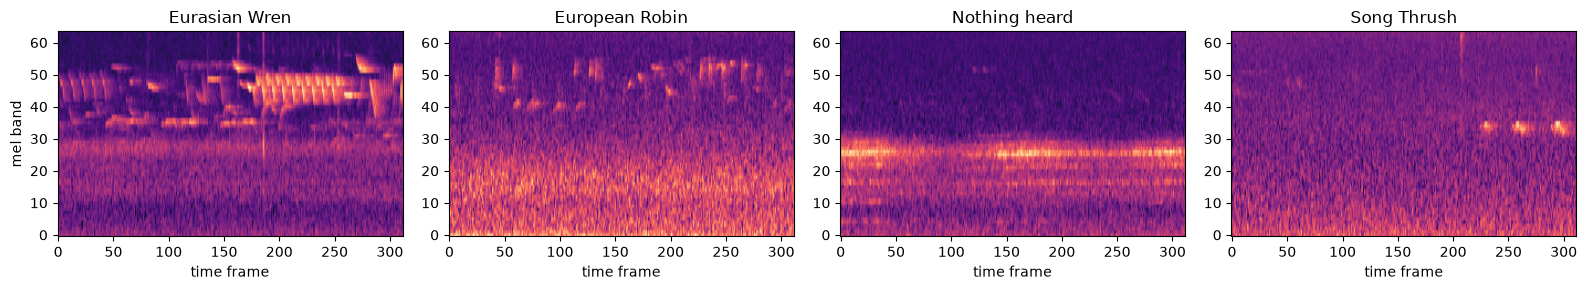

In [28]:
fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 3))
for c, ax in enumerate(axes):
    ax.imshow(X_lab[y_lab == c][0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(classes[c])
    ax.set_xlabel("time frame")
axes[0].set_ylabel("mel band")
plt.tight_layout()

Hold out 20% of the labelled clips so we can see how well the model generalises.

In [29]:
X_train, X_val, y_train, y_val = train_test_split(X_lab, y_lab, test_size=0.2, stratify=y_lab, random_state=0)
len(X_train), len(X_val)

(160, 40)

In [30]:
train_loader = DataLoader(TensorDataset(torch.tensor(X_train).unsqueeze(1), torch.tensor(y_train)), batch_size=16, shuffle=True)
X_val_t = torch.tensor(X_val).unsqueeze(1).to(device)
y_val_t = torch.tensor(y_val).to(device)

## Model

In [31]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),   # 16 x 32 x 156
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),  # 32 x 16 x 78
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),  # 64 x 8 x 39
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(nn.Linear(64 * 8 * 39, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


model = SmallCNN(len(classes)).to(device)
sum(p.numel() for p in model.parameters())

103172

## Training

In [32]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
n_epochs = 50

train_losses, val_losses, val_accs = [], [], []
for epoch in range(n_epochs):
    model.train()
    total = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
    train_losses.append(total / len(train_loader.dataset))

    model.eval()
    with torch.no_grad():
        logits = model(X_val_t)
        val_losses.append(loss_fn(logits, y_val_t).item())
        val_accs.append((logits.argmax(1) == y_val_t).float().mean().item())

    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1}: train loss {train_losses[-1]:.3f}, val loss {val_losses[-1]:.3f}, val acc {val_accs[-1]:.2f}")

epoch 10: train loss 0.824, val loss 1.024, val acc 0.57
epoch 20: train loss 0.458, val loss 0.950, val acc 0.60
epoch 30: train loss 0.262, val loss 1.112, val acc 0.73
epoch 40: train loss 0.144, val loss 1.165, val acc 0.73
epoch 50: train loss 0.040, val loss 1.533, val acc 0.73


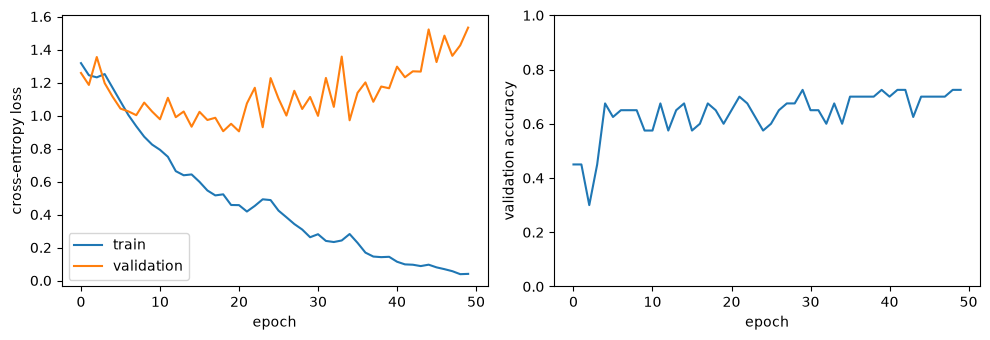

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(train_losses, label="train")
ax1.plot(val_losses, label="validation")
ax1.set_xlabel("epoch")
ax1.set_ylabel("cross-entropy loss")
ax1.legend()
ax2.plot(val_accs)
ax2.set_xlabel("epoch")
ax2.set_ylabel("validation accuracy")
ax2.set_ylim(0, 1)
plt.tight_layout()

## Predicting on the test set

Run your model on the 200 unlabelled test clips. Put your group name in the cell below before saving — the cell will not run without it.

In [34]:
test_paths = sorted((DATA_DIR / "test").glob("*.wav"))
test_files = [p.name for p in test_paths]
X_test = load_files(test_paths)
X_test.shape

(200, 64, 312)

In [35]:
model.eval()
with torch.no_grad():
    test_preds = model(torch.tensor(X_test).unsqueeze(1).to(device)).argmax(1).cpu().numpy()

pd.Series([classes[i] for i in test_preds]).value_counts()

Nothing heard     93
Eurasian Wren     60
Song Thrush       27
European Robin    20
Name: count, dtype: int64

In [36]:
GROUP_NAME = 'tested'

group = GROUP_NAME.strip()
out_path = ROOT / "test_results" / f"{group.replace(' ', '_')}_supervised.csv"
out_path.parent.mkdir(exist_ok=True)

results = pd.DataFrame({
    "filename": test_files,
    "species": [classes[i] for i in test_preds],
    "model": "supervised",
    "group": group,
})
results.to_csv(out_path, index=False)
print(f"Saved {len(results)} predictions to {out_path}")
results.head()

Saved 200 predictions to /gws/ssde/j25b/iecdt/bio_practicals/bioacoustic/test_results/tested_supervised.csv


,filename,species,model,group
0,A4_20250306_175100_c2.wav,Nothing heard,supervised,tested
1,A5-2_20250717_050800_c8.wav,Nothing heard,supervised,tested
2,A5_20250511_032600_c1.wav,Song Thrush,supervised,tested
3,B2-2_20250907_193700_c4.wav,Nothing heard,supervised,tested
4,B2_20250419_063900_c0.wav,Song Thrush,supervised,tested
